In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [3]:
# 1. CZĘŚĆ REGULARNA
N_regular = 4000
N_chaotic = 4000

n = np.arange(N_regular)

# Regularny sygnał okresowy
x_regular = np.sin(2 * np.pi * 0.03 * n)


# 2. CZĘŚĆ CHAOTYCZNA
x_chaotic = np.zeros(N_chaotic)
x_chaotic[0] = 0.2

r = 4.0

for i in range(N_chaotic - 1):
    x_chaotic[i + 1] = r * x_chaotic[i] * (1 - x_chaotic[i])


# 3. ŁĄCZENIE REŻIMÓW
x = np.concatenate([x_regular, x_chaotic])

N = len(x)
t = np.arange(N)

print(f"Liczba próbek: {N}")
print(f"Regularny fragment: 0–{N_regular-1}")
print(f"Chaotyczny fragment: {N_regular}–{N-1}")

Liczba próbek: 8000
Regularny fragment: 0–3999
Chaotyczny fragment: 4000–7999


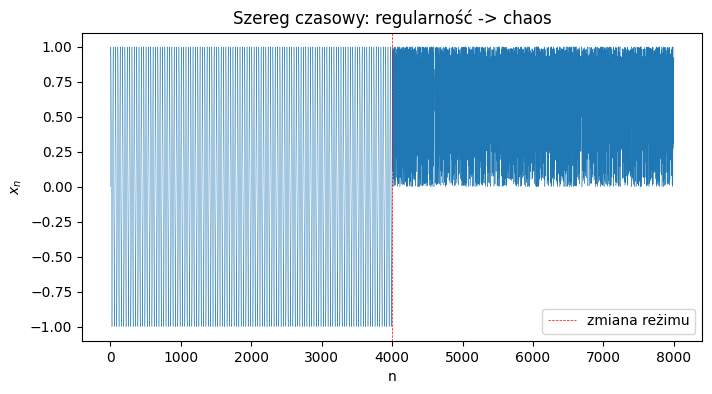

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(t, x, linewidth=0.3)

ax.axvline(
    N_regular,
    linestyle="--",
    linewidth=0.5,
    label="zmiana reżimu",
    color="red"
)

ax.set_xlabel("n")
ax.set_ylabel("$x_n$")
ax.set_title("Szereg czasowy: regularność -> chaos")
ax.legend()

plt.show()

In [8]:
def zero_one_trajectory(x, c):
    """
    Konstrukcja trajektorii p_n, q_n
    używanej w teście 0-1 dla chaosu.
    """
    
    n = np.arange(1, len(x) + 1)
    
    p = np.cumsum(x * np.cos(c * n))
    q = np.cumsum(x * np.sin(c * n))
    
    return p, q


# Parametr c.
# W praktyce wybiera się go zwykle z zakresu (0, pi).
c = 2.3

p, q = zero_one_trajectory(x, c)

print("Gotowe.")
print("Liczba punktów trajektorii:", len(p))

Gotowe.
Liczba punktów trajektorii: 8000


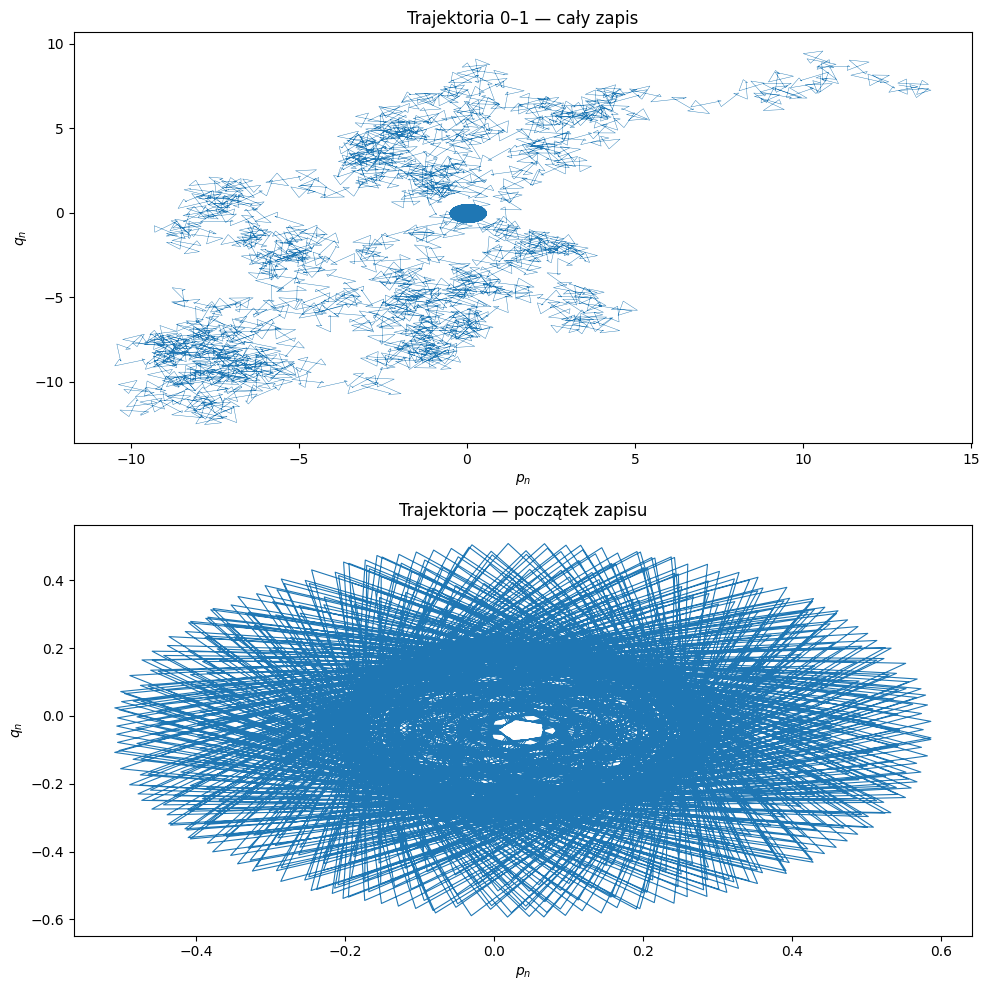

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10))

# Cała trajektoria
axes[0].plot(p, q, linewidth=0.3)
axes[0].set_xlabel("$p_n$")
axes[0].set_ylabel("$q_n$")
axes[0].set_title("Trajektoria 0–1 — cały zapis")

# Początek
axes[1].plot(p[:1000], q[:1000], linewidth=0.8)
axes[1].set_xlabel("$p_n$")
axes[1].set_ylabel("$q_n$")
axes[1].set_title("Trajektoria — początek zapisu")

plt.tight_layout()
plt.show()

In [15]:
def mean_square_displacement(p, q, max_lag=1000):
    """
    Oblicza średnie przemieszczenie kwadratowe M(m).
    """
    
    lags = np.arange(1, max_lag + 1)
    M = np.empty_like(lags, dtype=float)
    
    for i, m in enumerate(lags):
        dp = p[m:] - p[:-m]
        dq = q[m:] - q[:-m]
        
        M[i] = np.mean(dp**2 + dq**2)
    
    return lags, M


lags, M = mean_square_displacement(
    p,
    q,
    max_lag=1000
)

# Dopasowanie prostej w skali log-log
fit_range = (lags > 50) & (lags < 800)

slope, intercept = np.polyfit(
    np.log(lags[fit_range]),
    np.log(M[fit_range]),
    1
)

K = slope

print(f"Przybliżone K = {K:.3f}")

Przybliżone K = 0.780


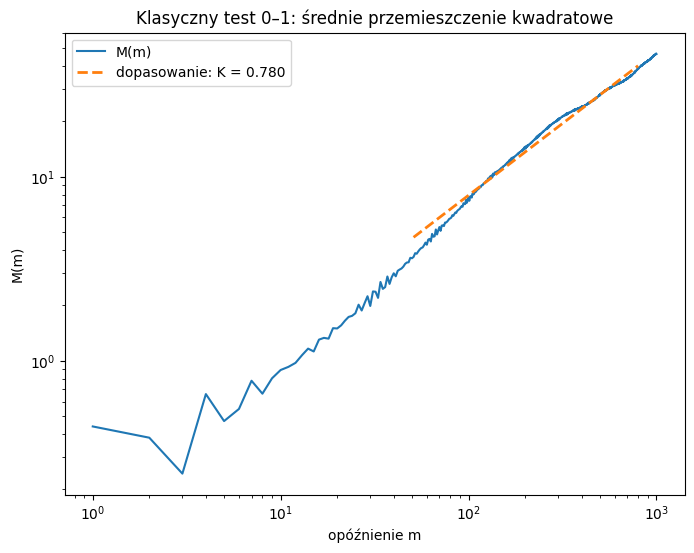

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.loglog(lags, M, label="M(m)")

ax.loglog(
    lags[fit_range],
    np.exp(intercept) * lags[fit_range]**slope,
    linestyle="--",
    linewidth=2,
    label=f"dopasowanie: K = {K:.3f}"
)

ax.set_xlabel("opóźnienie m")
ax.set_ylabel("M(m)")
ax.set_title("Klasyczny test 0–1: średnie przemieszczenie kwadratowe")
ax.legend()

plt.show()

In [18]:
def segment_features(p, q):
    """
    Dla każdego kolejnego odcinka trajektorii
    oblicza jego długość i kąt.
    """
    
    dp = np.diff(p)
    dq = np.diff(q)
    
    length = np.sqrt(dp**2 + dq**2)
    angle = np.arctan2(dq, dp)
    
    return length, angle


length, angle = segment_features(p, q)

print("Liczba odcinków:", len(length))
print("Średnia długość:", np.mean(length))

Liczba odcinków: 7999
Średnia długość: 0.570541124260079


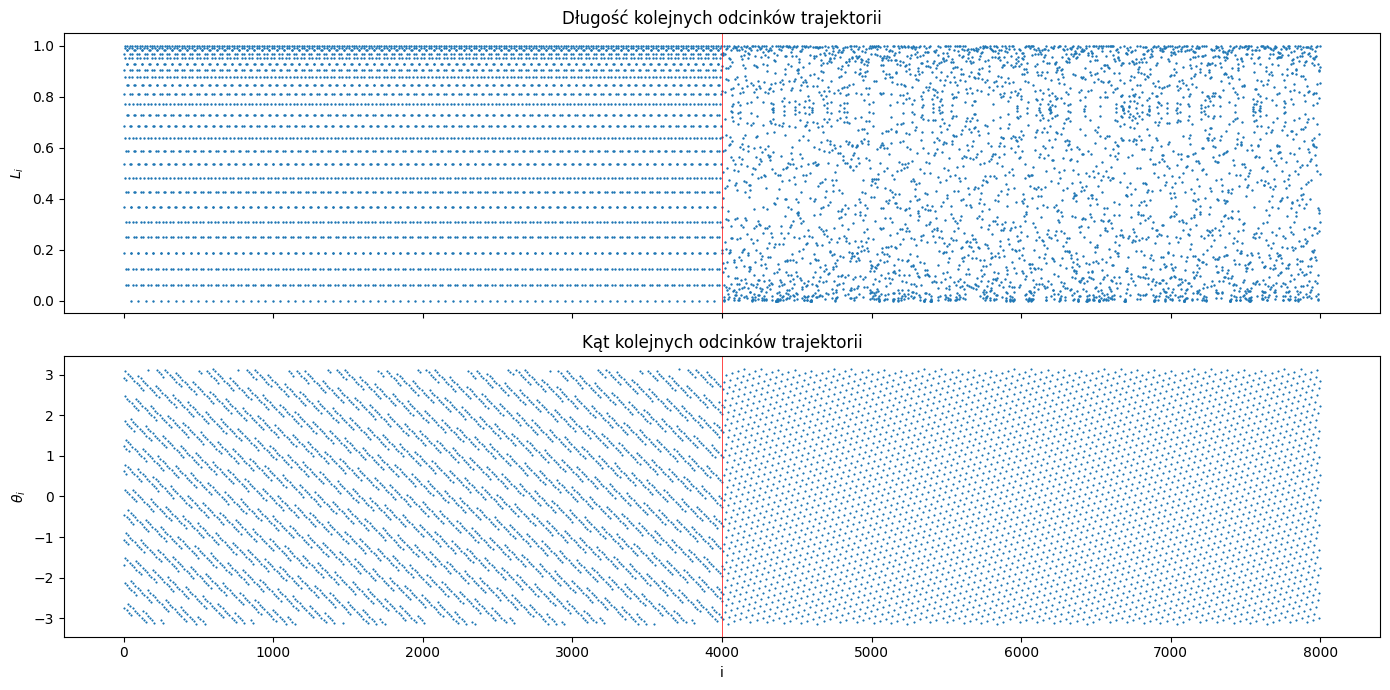

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].scatter(range(len(length)), length, s=1, linewidth=0.7)
axes[0].axvline(N_regular, linestyle="-", linewidth=0.5, color="red")
axes[0].set_ylabel("$L_i$")
axes[0].set_title("Długość kolejnych odcinków trajektorii")

axes[1].scatter(range(len(angle)), angle, s=1, linewidth=0.5)
axes[1].axvline(N_regular, linestyle="-", linewidth=0.5, color="red")
axes[1].set_xlabel("i")
axes[1].set_ylabel("$\\theta_i$")
axes[1].set_title("Kąt kolejnych odcinków trajektorii")

plt.tight_layout()
plt.show()

In [25]:
def window_features(length, angle, window_size=400):
    """
    Oblicza cechy trajektorii w kolejnych oknach.
    """
    
    centers = []
    mean_length = []
    std_length = []
    mean_angle_change = []
    
    for start in range(0, len(length) - window_size + 1, window_size):
        
        stop = start + window_size
        
        L = length[start:stop]
        A = angle[start:stop]
        
        # Środek masy trajektorii w oknie
        # liczymy później osobno z p i q
        
        centers.append(start + window_size / 2)
        mean_length.append(np.mean(L))
        std_length.append(np.std(L))
        
        # Zmiana kąta pomiędzy kolejnymi odcinkami
        dA = np.angle(np.exp(1j * np.diff(A)))
        mean_angle_change.append(np.mean(np.abs(dA)))
    
    return (
        np.array(centers),
        np.array(mean_length),
        np.array(std_length),
        np.array(mean_angle_change)
    )


centers, mean_L, std_L, mean_dA = window_features(
    length,
    angle,
    window_size=400
)

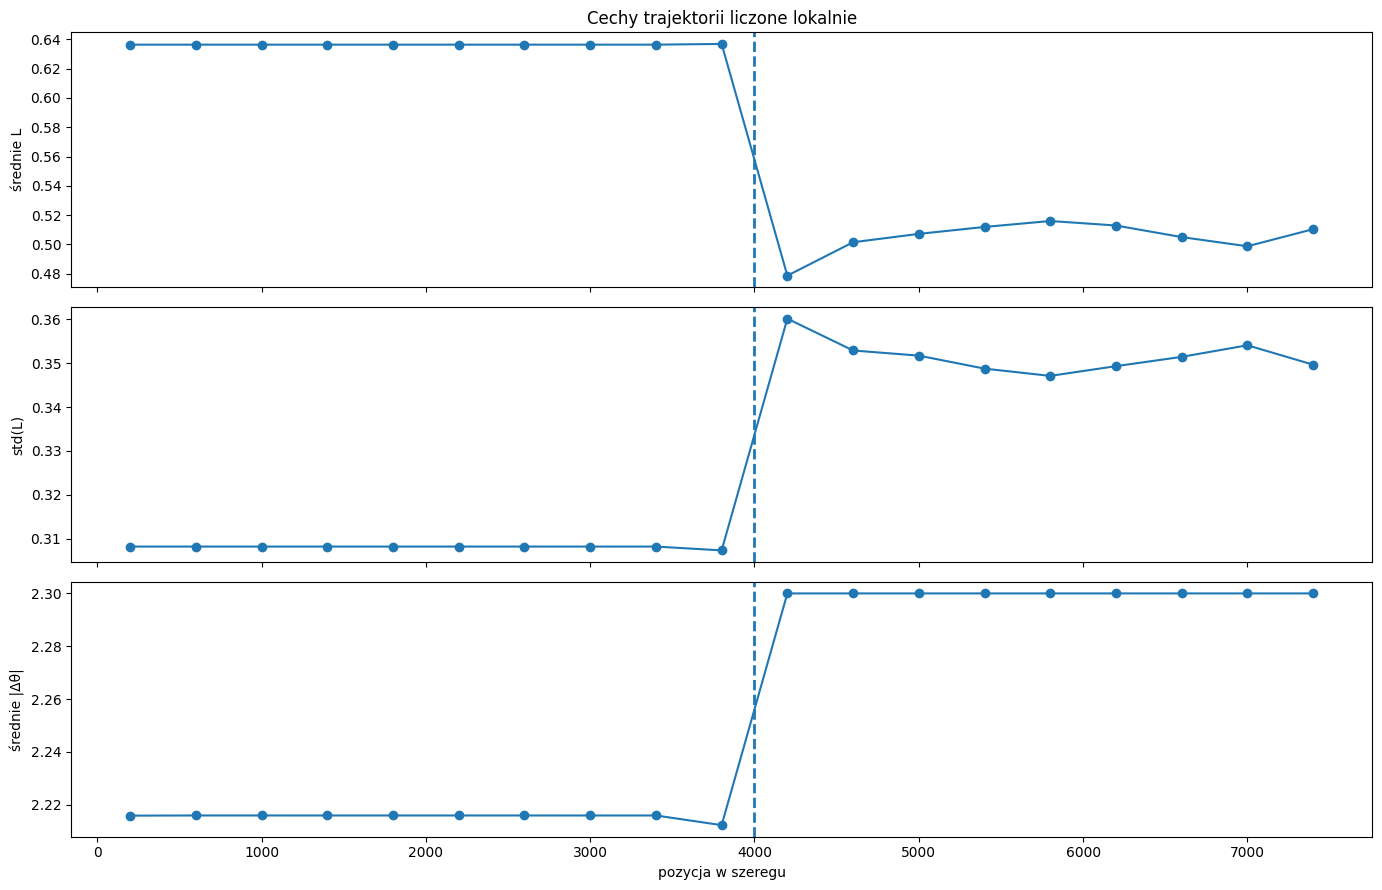

In [26]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

axes[0].plot(centers, mean_L, marker="o")
axes[0].set_ylabel("średnie L")
axes[0].set_title("Cechy trajektorii liczone lokalnie")

axes[1].plot(centers, std_L, marker="o")
axes[1].set_ylabel("std(L)")

axes[2].plot(centers, mean_dA, marker="o")
axes[2].set_ylabel("średnie |Δθ|")
axes[2].set_xlabel("pozycja w szeregu")

for ax in axes:
    ax.axvline(
        N_regular,
        linestyle="--",
        linewidth=2
    )

plt.tight_layout()
plt.show()

In [27]:
def center_of_mass_windows(p, q, window_size=400):
    """
    Środek masy trajektorii w kolejnych oknach.
    """
    
    centers = []
    cx = []
    cy = []
    
    for start in range(0, len(p) - window_size + 1, window_size):
        
        stop = start + window_size
        
        centers.append(start + window_size / 2)
        cx.append(np.mean(p[start:stop]))
        cy.append(np.mean(q[start:stop]))
    
    return (
        np.array(centers),
        np.array(cx),
        np.array(cy)
    )


centers_cm, cx, cy = center_of_mass_windows(
    p,
    q,
    window_size=400
)

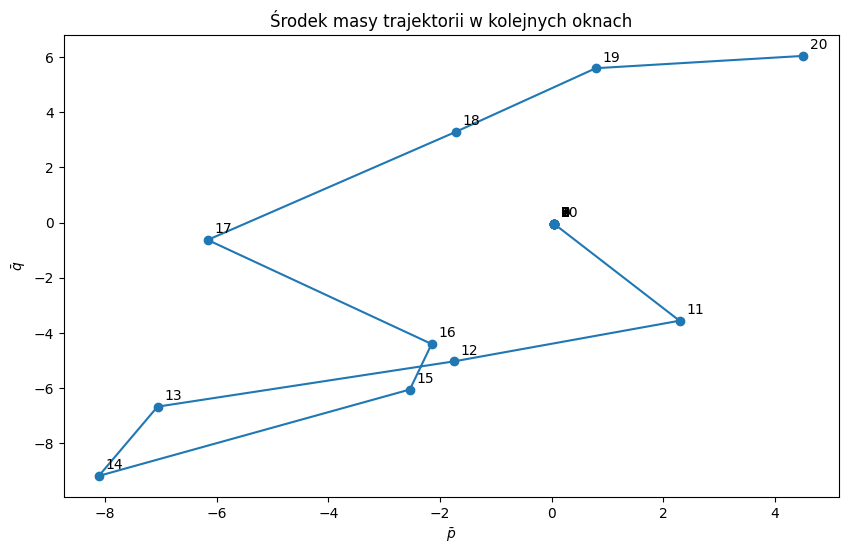

In [28]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    cx,
    cy,
    marker="o",
    linewidth=1.5
)

for i in range(len(cx)):
    ax.annotate(
        str(i + 1),
        (cx[i], cy[i]),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_xlabel("$\\bar p$")
ax.set_ylabel("$\\bar q$")
ax.set_title("Środek masy trajektorii w kolejnych oknach")

plt.show()

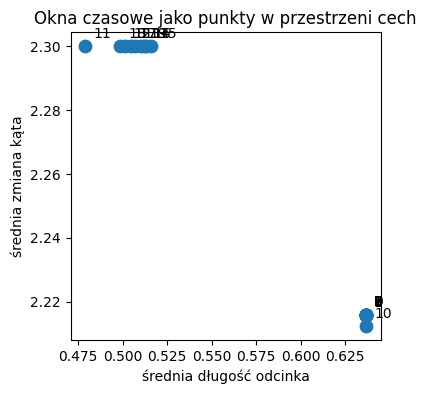

In [30]:
fig, ax = plt.subplots(figsize=(4, 4))

ax.scatter(
    mean_L,
    mean_dA,
    s=80
)

for i, (xx, yy) in enumerate(zip(mean_L, mean_dA)):
    ax.annotate(
        f"{i+1}",
        (xx, yy),
        xytext=(6, 6),
        textcoords="offset points"
    )

ax.set_xlabel("średnia długość odcinka")
ax.set_ylabel("średnia zmiana kąta")
ax.set_title("Okna czasowe jako punkty w przestrzeni cech")

plt.show()

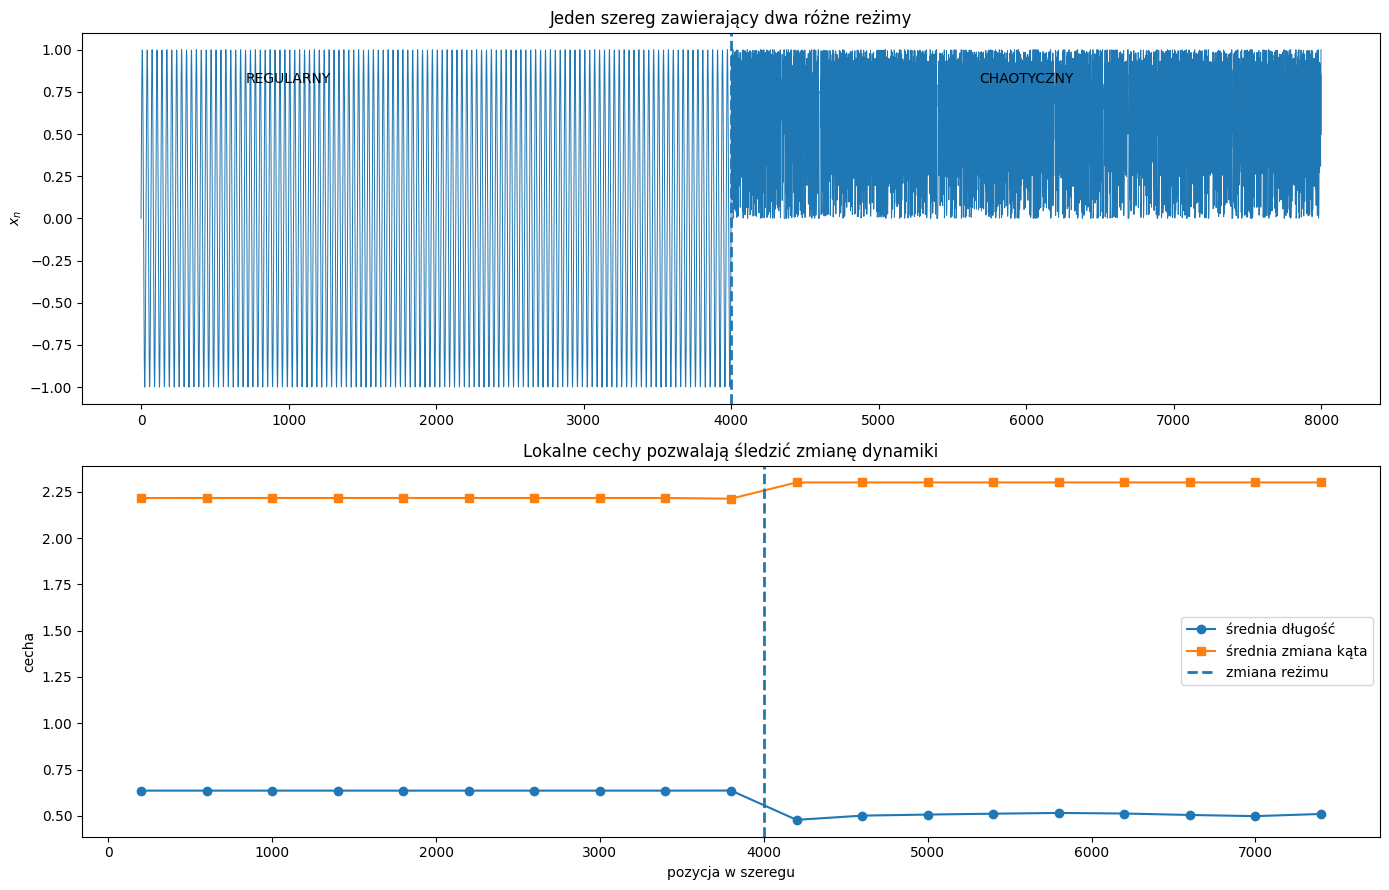

In [31]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# ---------------------------------------------------------
# GÓRA — pojedyncze K
# ---------------------------------------------------------

axes[0].plot(t, x, linewidth=0.7)

axes[0].axvline(
    N_regular,
    linestyle="--",
    linewidth=2
)

axes[0].text(
    N_regular * 0.25,
    np.max(x) * 0.8,
    "REGULARNY",
    ha="center"
)

axes[0].text(
    N_regular + N_chaotic * 0.5,
    np.max(x) * 0.8,
    "CHAOTYCZNY",
    ha="center"
)

axes[0].set_ylabel("$x_n$")
axes[0].set_title(
    "Jeden szereg zawierający dwa różne reżimy"
)


# ---------------------------------------------------------
# DÓŁ — lokalne cechy
# ---------------------------------------------------------

axes[1].plot(
    centers,
    mean_L,
    marker="o",
    label="średnia długość"
)

axes[1].plot(
    centers,
    mean_dA,
    marker="s",
    label="średnia zmiana kąta"
)

axes[1].axvline(
    N_regular,
    linestyle="--",
    linewidth=2,
    label="zmiana reżimu"
)

axes[1].set_xlabel("pozycja w szeregu")
axes[1].set_ylabel("cecha")
axes[1].set_title(
    "Lokalne cechy pozwalają śledzić zmianę dynamiki"
)

axes[1].legend()

plt.tight_layout()
plt.show()

# Reżimy dynamiki: 
### fixed point → periodic → quasiperiodic → chaos → hyperchaos

W dynamice układów możemy spotkać różne jakościowo rodzaje zachowania.

W tym notebooku zobaczymy ideowo pięć przypadków:

1. **Fixed point** — punkt stały
2. **Periodic** — ruch okresowy
3. **Quasiperiodic** — ruch quasi-okresowy
4. **Chaos** — chaos
5. **Hyperchaos** — hiperchaos

Najważniejsza idea:

- fixed point → układ przestaje się zmieniać,
- periodic → układ powtarza dokładnie ten sam cykl,
- quasiperiodic → występuje kilka niezależnych częstości i ruch nie powtarza się dokładnie,
- chaos → deterministyczny, ale bardzo wrażliwy na warunki początkowe ruch,
- hyperchaos → chaos o większej złożoności, charakteryzujący się co najmniej **dwoma dodatnimi wykładnikami Lapunowa**.

Nie należy utożsamiać:

> "bardziej nieregularny wykres = hiperchaos"

Formalna klasyfikacja wymaga analizy dynamiki układu.

---

## 1. Fixed point — punkt stały

Punkt stały to stan, w którym układ po pewnym czasie przestaje się zmieniać.

Formalnie:

$$
x_{n+1}=x_n=x^*
$$

Przykład:

$$
x_{n+1}=0.8x_n
$$

Dla dowolnego początkowego $x_0$:

$$
x_n \rightarrow 0.
$$

Zatem:

$$
x^*=0
$$

jest punktem stałym.

### Co widzimy?

Na wykresie trajektoria zbliża się do jednej wartości i pozostaje tam.

Nie ma oscylacji, chaosu ani ruchu po orbicie.

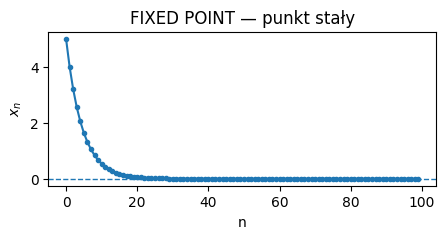

In [37]:
N = 100

x = np.zeros(N)
x[0] = 5.0

for n in range(N - 1):
    x[n + 1] = 0.8 * x[n]

plt.figure(figsize=(5, 2))
plt.plot(x, marker="o", markersize=3)
plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("n")
plt.ylabel("$x_n$")
plt.title("FIXED POINT — punkt stały")

plt.show()

## 2. Periodic — ruch okresowy

W ruchu okresowym układ nie pozostaje w jednym punkcie.

Zamiast tego powtarza swój stan po pewnym czasie $T$:

$$
x(t+T)=x(t).
$$

Dla szeregu dyskretnego:

$$
x_{n+P}=x_n,
$$

gdzie $P$ jest okresem.

Przykład:

$$
x_n=\sin(\omega n).
$$

### Najważniejsza cecha

Po odpowiednim czasie układ wraca dokładnie do tego samego stanu.

Dlatego:

$$
\text{periodic} = \text{dokładne powtarzanie}.
$$

Na wykresie czasowym widzimy regularną oscylację.

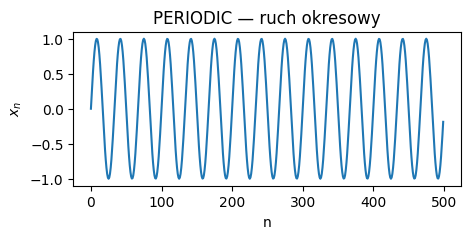

In [38]:
N = 500

n = np.arange(N)

x = np.sin(2 * np.pi * 0.03 * n)

plt.figure(figsize=(5, 2))
plt.plot(n, x)

plt.xlabel("n")
plt.ylabel("$x_n$")
plt.title("PERIODIC — ruch okresowy")

plt.show()

## 3. Quasiperiodic — ruch quasi-okresowy

Ruch quasi-okresowy jest regularny, ale nie posiada jednego wspólnego okresu.

Możemy mieć np.:

$$
x(t)=
\sin(\omega_1 t)
+
0.5\sin(\omega_2 t)
$$

gdzie:

$$
\frac{\omega_1}{\omega_2}
$$

jest liczbą niewymierną.

Wtedy nie istnieje takie $T$, dla którego:

$$
x(t+T)=x(t)
$$

dla wszystkich $t$.

### Kluczowa różnica

**Periodic:**

> układ dokładnie wraca do poprzedniego stanu.

**Quasiperiodic:**

> układ porusza się regularnie, ale nigdy dokładnie nie powtarza całego stanu.

Dlatego quasi-okresowość nie oznacza chaosu.

Ruch może być całkowicie deterministyczny i przewidywalny, mimo że nie jest okresowy.

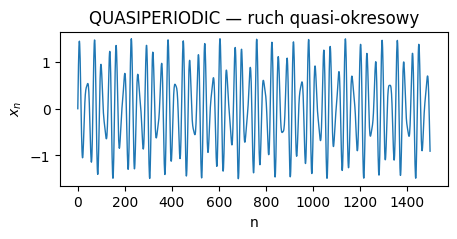

In [39]:
N = 1500

n = np.arange(N)

omega1 = 0.20
omega2 = 0.20 * np.sqrt(2)

x = (
    np.sin(omega1 * n)
    + 0.5 * np.sin(omega2 * n)
)

plt.figure(figsize=(5, 2))
plt.plot(n, x, linewidth=1)

plt.xlabel("n")
plt.ylabel("$x_n$")
plt.title("QUASIPERIODIC — ruch quasi-okresowy")

plt.show()

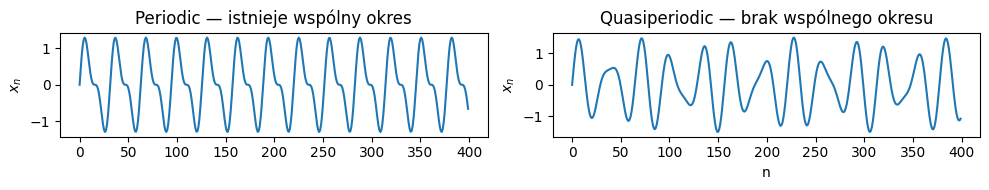

In [41]:
N = 400
n = np.arange(N)

# PERIODIC
x_periodic = (
    np.sin(0.2 * n)
    + 0.5 * np.sin(0.4 * n)
)

# QUASIPERIODIC
x_quasi = (
    np.sin(0.2 * n)
    + 0.5 * np.sin(0.2 * np.sqrt(2) * n)
)

fig, axes = plt.subplots(1, 2, figsize=(10, 2))

axes[0].plot(n, x_periodic)
axes[0].set_title("Periodic — istnieje wspólny okres")
axes[0].set_ylabel("$x_n$")

axes[1].plot(n, x_quasi)
axes[1].set_title("Quasiperiodic — brak wspólnego okresu")
axes[1].set_ylabel("$x_n$")
axes[1].set_xlabel("n")

plt.tight_layout()
plt.show()

## 4. Chaos

Chaos jest jakościowo inny od zwykłej nieregularności.

Układ może być całkowicie deterministyczny:

$$
x_{n+1}=f(x_n)
$$

a mimo to zachowywać się w sposób bardzo trudny do przewidywania.

Kluczową cechą jest **wrażliwość na warunki początkowe**.

Jeżeli:

$$
x_0
$$

oraz

$$
x_0+\delta
$$

różnią się bardzo niewiele, ich trajektorie mogą po pewnym czasie stać się bardzo odległe.

W uproszczeniu:

$$
\delta(t)\sim\delta_0e^{\lambda t}
$$

gdzie dodatni wykładnik Lapunowa:

$$
\lambda>0
$$

oznacza rozbieganie się bliskich trajektorii.

### Ważne

Chaos ≠ losowość.

Chaos może powstawać w całkowicie deterministycznym układzie.

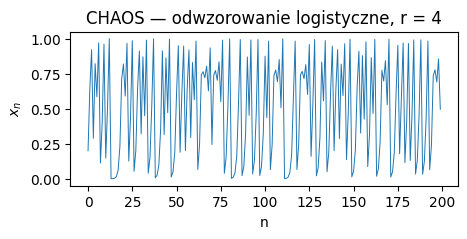

In [44]:
N = 200

r = 4.0
x = np.zeros(N)

x[0] = 0.2

for n in range(N - 1):
    x[n + 1] = r * x[n] * (1 - x[n])

plt.figure(figsize=(5, 2))
plt.plot(x, linewidth=0.7)

plt.xlabel("n")
plt.ylabel("$x_n$")
plt.title("CHAOS — odwzorowanie logistyczne, r = 4")

plt.show()

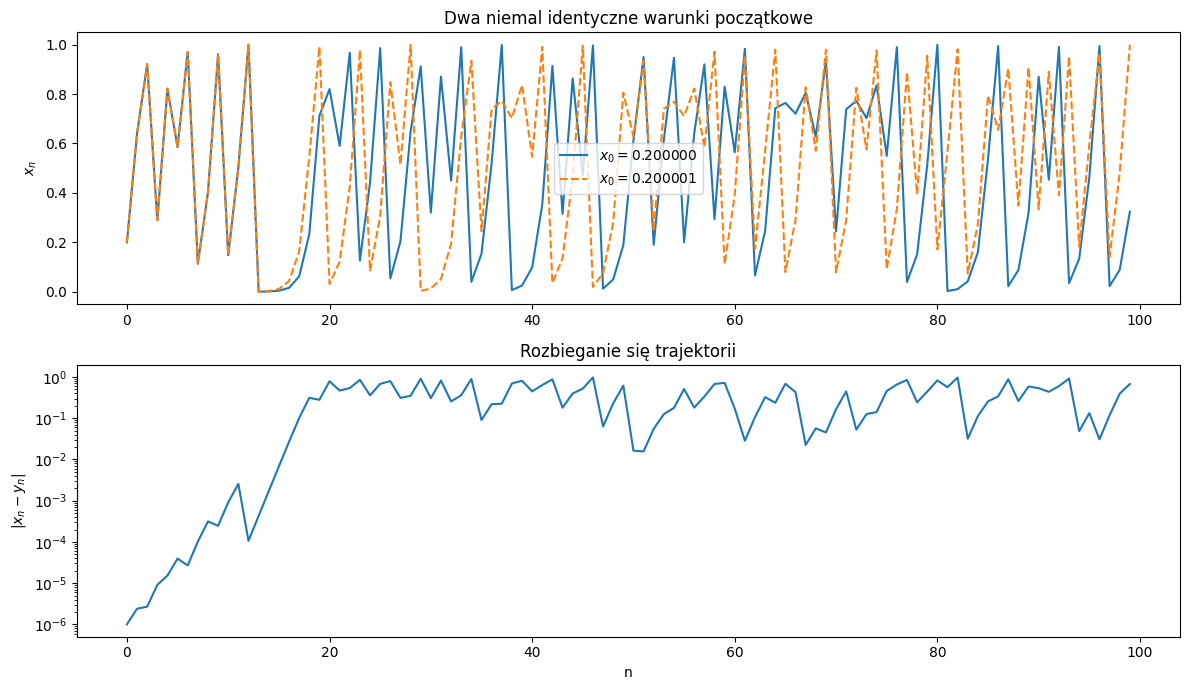

In [45]:
N = 100

r = 4.0

x1 = np.zeros(N)
x2 = np.zeros(N)

x1[0] = 0.200000
x2[0] = 0.200001

for n in range(N - 1):
    x1[n + 1] = r * x1[n] * (1 - x1[n])
    x2[n + 1] = r * x2[n] * (1 - x2[n])

difference = np.abs(x1 - x2)

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(x1, label="$x_0=0.200000$")
axes[0].plot(x2, linestyle="--", label="$x_0=0.200001$")

axes[0].set_ylabel("$x_n$")
axes[0].set_title("Dwa niemal identyczne warunki początkowe")
axes[0].legend()

axes[1].semilogy(difference)

axes[1].set_xlabel("n")
axes[1].set_ylabel("$|x_n-y_n|$")
axes[1].set_title("Rozbieganie się trajektorii")

plt.tight_layout()
plt.show()

## 5. Hyperchaos — hiperchaos

Hiperchaos wymaga układu o odpowiednio dużym wymiarze.

Patrzymy na wykładniki Lapunowa:

$$
\lambda_1,\lambda_2,\lambda_3,\ldots
$$

### Chaos

Wystarczy co najmniej jeden dodatni wykładnik:

$$
\lambda_1>0.
$$

### Hyperchaos

Potrzebne są co najmniej dwa dodatnie wykładniki:

$$
\lambda_1>0,
\qquad
\lambda_2>0.
$$

Interpretacja geometryczna:

- dodatni wykładnik oznacza rozciąganie trajektorii w pewnym kierunku,
- dwa dodatnie wykładniki oznaczają rozciąganie w co najmniej dwóch niezależnych kierunkach.

Dlatego hiperchaos może występować dopiero w układach o odpowiednio dużym wymiarze.

### Bardzo ważne

Nie można rozpoznać hiperchaosu tylko na podstawie tego, że wykres wygląda "bardziej chaotycznie".

Potrzebna jest analiza dynamiki, np. wykładników Lapunowa.

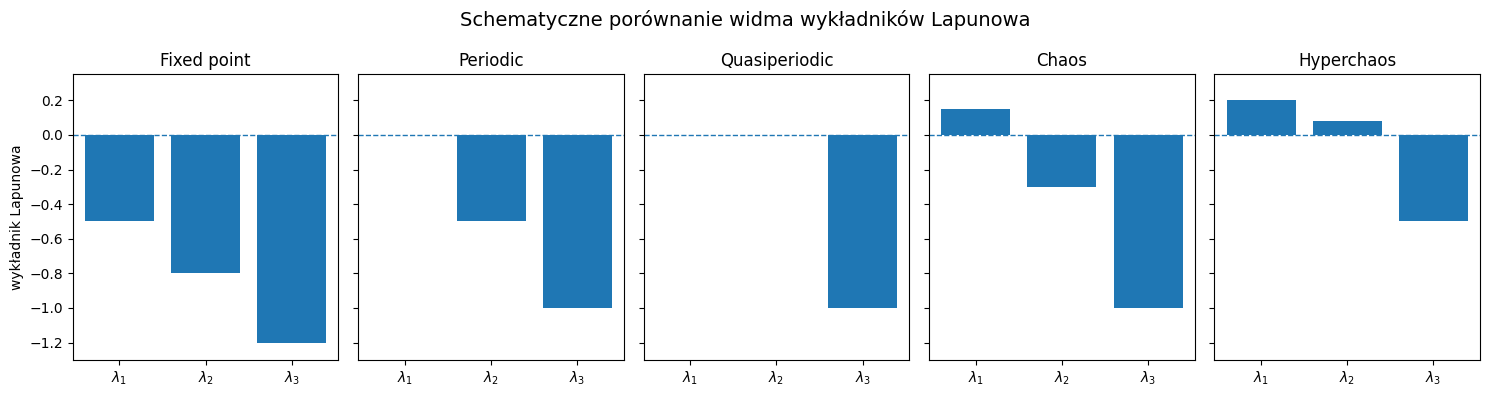

In [46]:
regimes = [
    "Fixed point",
    "Periodic",
    "Quasiperiodic",
    "Chaos",
    "Hyperchaos"
]

lyapunov_examples = [
    [-0.5, -0.8, -1.2],
    [0.0, -0.5, -1.0],
    [0.0, 0.0, -1.0],
    [0.15, -0.3, -1.0],
    [0.20, 0.08, -0.5]
]

fig, axes = plt.subplots(1, 5, figsize=(15, 4), sharey=True)

for ax, name, exponents in zip(
    axes,
    regimes,
    lyapunov_examples
):
    
    ax.axhline(
        0,
        linestyle="--",
        linewidth=1
    )
    
    ax.bar(
        range(len(exponents)),
        exponents
    )
    
    ax.set_title(name)
    ax.set_xticks(range(len(exponents)))
    ax.set_xticklabels(
        [f"$λ_{i+1}$" for i in range(len(exponents))]
    )
    
    ax.set_ylim(-1.3, 0.35)

axes[0].set_ylabel("wykładnik Lapunowa")

fig.suptitle(
    "Schematyczne porównanie widma wykładników Lapunowa",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Podsumowanie

| Reżim | Czy układ się zmienia? | Czy ruch się powtarza? | Chaos? | Dodatnie wykładniki Lapunowa |
|---|---|---|---|---|
| **Fixed point** | Nie | — | Nie | 0 |
| **Periodic** | Tak | Tak, dokładnie | Nie | 0 |
| **Quasiperiodic** | Tak | Nie dokładnie | Nie | 0 |
| **Chaos** | Tak | Nie | Tak | ≥ 1 |
| **Hyperchaos** | Tak | Nie | Tak | ≥ 2 |

Najważniejszy schemat:

$$
\boxed{
\text{Fixed point}
\rightarrow
\text{Periodic}
\rightarrow
\text{Quasiperiodic}
\rightarrow
\text{Chaos}
\rightarrow
\text{Hyperchaos}
}
$$

nie oznacza jednej uniwersalnej ścieżki, którą każdy układ musi przejść.

Są to różne **reżimy dynamiki**, które mogą występować w zależności od parametrów konkretnego układu.

| Reżim             | Przykładowe \(\lambda\) | Co się dzieje?              |
| ----------------- | ----------------------- | --------------------------- |
| **Fixed point**   | \(-,-,-\)               | wszystko jest przyciągane   |
| **Periodic**      | \(0,-,-\)               | ruch po stabilnej orbicie   |
| **Quasiperiodic** | \(0,0,-\)               | ruch regularny na torusie   |
| **Chaos**         | \(+,-,-\)               | rozbieganie w 1 kierunku    |
| **Hyperchaos**    | \(+,+,-\)               | rozbieganie w ≥2 kierunkach |


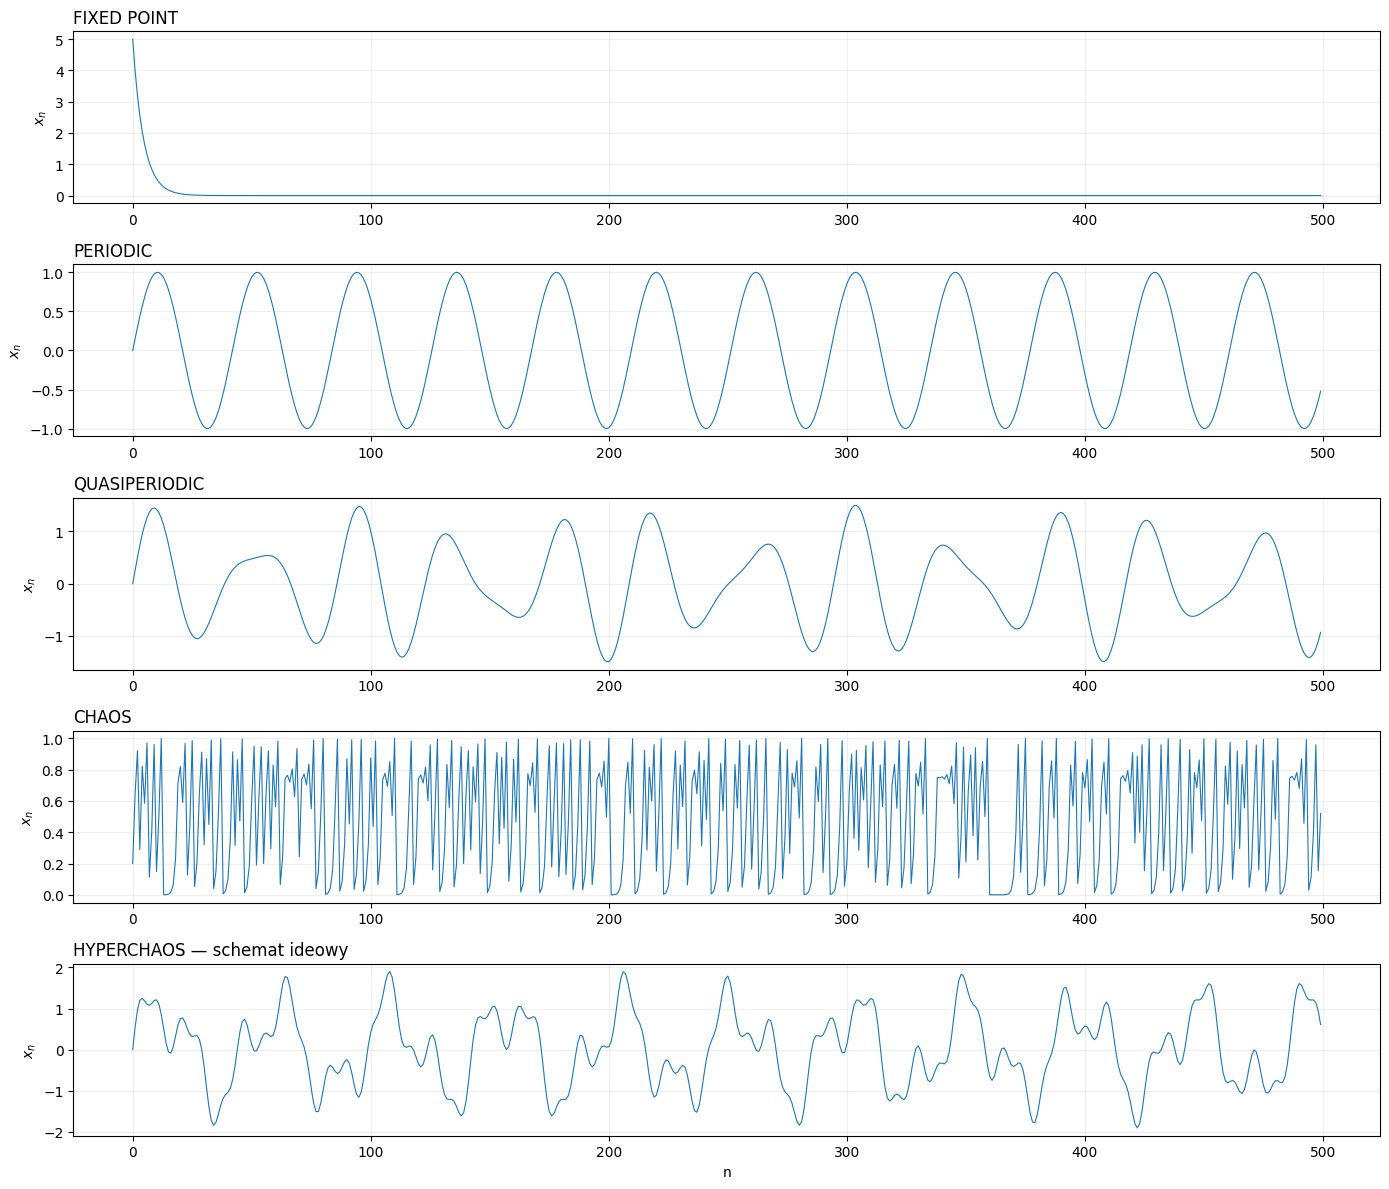

In [47]:
fig, axes = plt.subplots(5, 1, figsize=(14, 12))

N = 500
n = np.arange(N)

# 1. FIXED POINT
x_fixed = 5 * 0.8**n

# 2. PERIODIC
x_periodic = np.sin(0.15 * n)

# 3. QUASIPERIODIC
x_quasi = (
    np.sin(0.15 * n)
    + 0.5 * np.sin(0.15 * np.sqrt(2) * n)
)

# 4. CHAOS
x_chaos = np.zeros(N)
x_chaos[0] = 0.2

for i in range(N - 1):
    x_chaos[i + 1] = (
        4 * x_chaos[i] * (1 - x_chaos[i])
    )

# 5. Schematyczny sygnał hiperchaotyczny
# Nie traktujemy tego jako dowodu hiperchaosu.
# To tylko wizualizacja złożonego sygnału.
x_hyper = (
    np.sin(0.13 * n)
    + 0.7 * np.sin(0.31 * n)
    + 0.3 * np.sin(0.71 * n)
)

signals = [
    x_fixed,
    x_periodic,
    x_quasi,
    x_chaos,
    x_hyper
]

titles = [
    "FIXED POINT",
    "PERIODIC",
    "QUASIPERIODIC",
    "CHAOS",
    "HYPERCHAOS — schemat ideowy"
]

for ax, signal, title in zip(axes, signals, titles):
    
    ax.plot(n, signal, linewidth=0.8)
    
    ax.set_ylabel("$x_n$")
    ax.set_title(title, loc="left")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("n")

plt.tight_layout()
plt.show()